[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C01/E01-2_Traitement_Acier_CORRIGE.ipynb)

# Résistance à la traction d'un acier traité : apprendre sans apprendre par cœur

## Le contexte

Un atelier de traitement thermique livre des lots d'acier dont la résistance à la traction doit respecter une spécification. La vérifier suppose aujourd'hui un essai destructif sur éprouvette : c'est long, coûteux, et cela consomme de la matière.

Peut-on estimer cette résistance à partir des paramètres déjà enregistrés en fabrication (température de traitement, temps de trempe, composition chimique, nuance), avec une erreur assez faible pour trier les lots avant essai ?

C'est un problème de régression : la grandeur à prédire est un nombre, en MPa.

Défi : prédire `resistance_traction_MPa` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ n'utilise qu'une seule variable, la température du palier de traitement, et atteint un R² de 0,878 : à vous d'ajouter les autres. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Traitement_Acier.xlsx`, dans le dossier `donnees` du dépôt : 150 lots, 6 colonnes. Une ligne est un lot.

| Colonne | Signification | Unité |
|---|---|---|
| `temperature_traitement_thermique_C` | température du palier de traitement | °C |
| `temps_trempe_min` | durée de la trempe | min |
| `teneur_carbone_pourcent` | teneur en carbone | % massique |
| `taux_chrome_pourcent` | taux de chrome | % massique |
| `type_alliage` | nuance : `Acier_Doux`, `Acier_Moyen` ou `Acier_Dur` | catégorie |
| `resistance_traction_MPa` | cible : résistance à la traction | MPa |

Ce jeu est un support pédagogique, construit par transformation d'un jeu public (Iris, UCI Machine Learning Repository, licence CC BY 4.0). Les ordres de grandeur sont plausibles pour un acier faiblement allié, mais ce ne sont pas des mesures d'essais : le jeu enseigne une méthode, et aucune conclusion métallurgique n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions et ses cases vides avant toute modélisation. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Traitement_Acier.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Traitement_Acier.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)
print("dimensions :", df.shape)
print("cases vides au total :", int(df.isna().sum().sum()))
print(df["type_alliage"].value_counts().to_string())
df.head()

dimensions : (150, 6)
cases vides au total : 0
type_alliage
Acier_Doux     50
Acier_Moyen    50
Acier_Dur      50


,temperature_traitement_thermique_C,temps_trempe_min,teneur_carbone_pourcent,taux_chrome_pourcent,type_alliage,resistance_traction_MPa
0,1208,40,0.268,0.72,Acier_Doux,611.2
1,1192,35,0.268,0.72,Acier_Doux,577.3
2,1176,37,0.256,0.72,Acier_Doux,588.2
3,1168,36,0.280,0.72,Acier_Doux,613.7
4,1200,41,0.268,0.72,Acier_Doux,590.9


Lecture du résultat : 150 lots, 6 colonnes, aucune case vide, 50 lots par nuance. Le jeu est propre, ce qui est rare sur des relevés réels.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Traitement_Acier.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : choisir la variable de départ

On calcule la corrélation de chaque variable numérique avec la résistance. Le modèle de départ n'en retient qu'une : la température du palier de traitement, grandeur que l'atelier règle directement et par laquelle le revenu pilote la résistance. Elle n'est pas la plus corrélée : ce choix laisse de la marge à qui ajoute les autres variables. On trace la résistance en fonction de cette température, en distinguant les trois nuances.

temperature_traitement_thermique_C    0.904
temps_trempe_min                     -0.330
teneur_carbone_pourcent               0.981
taux_chrome_pourcent                  0.968


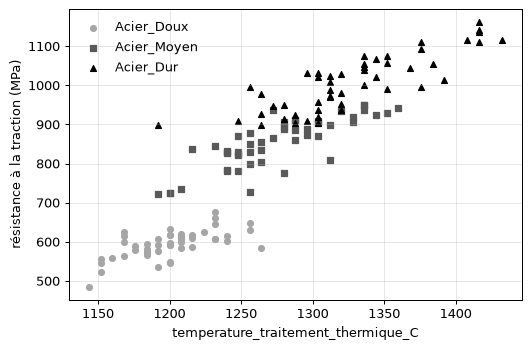

In [2]:
cible = "resistance_traction_MPa"
correlations = df.corr(numeric_only=True)[cible].drop(cible)
print(correlations.round(3).to_string())

# Variable du modèle de départ : la température du palier de traitement.
variable = "temperature_traitement_thermique_C"

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for nuance, marqueur, gris in [("Acier_Doux", "o", "0.65"), ("Acier_Moyen", "s", "0.35"), ("Acier_Dur", "^", "0.0")]:
    lots = df[df["type_alliage"] == nuance]
    ax.scatter(lots[variable], lots[cible], s=22, marker=marqueur, color=gris, label=nuance)
ax.set_xlabel(variable)
ax.set_ylabel("résistance à la traction (MPa)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

Lecture du résultat : la teneur en carbone arrive en tête, suivie du taux de chrome et de la température, tandis que le temps de trempe est faiblement et négativement corrélé. Avec la température, la résistance monte nettement, mais le nuage est plus épais et les nuances se recouvrent : une droite est crédible, sans être parfaite. C'est un bon point de départ.

### Étape 3 : séparer l'apprentissage et le test

Un quart des lots est mis de côté avant tout apprentissage. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent.

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE)
print("apprentissage :", len(X_train), "lots")
print("test :", len(X_test), "lots")

apprentissage : 112 lots
test : 38 lots


### Étape 4 : construire le modèle de départ

Le modèle de départ est volontairement simple : une régression linéaire qui cherche la droite minimisant la somme des carrés des écarts, avec la seule variable choisie à l'étape 2. Il apprend sur `X_train` seul. Les autres colonnes, dont le carbone, le chrome et la nuance, sont laissées de côté : elles sont votre marge de progression.

In [4]:
# Solution :
from sklearn.linear_model import LinearRegression

modele = LinearRegression()
modele.fit(X_train[[variable]], y_train)
# Fin de la solution

LinearRegression()

### Étape 5 : mesurer sur la base de test

Le modèle prédit les lots qu'il n'a jamais vus. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en MPa, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE).

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test[[variable]])
print(f"R² : {r2_score(y_test, y_pred):.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.1f} MPa")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.1f} MPa")
print(f"résistance moyenne de la base de test : {y_test.mean():.1f} MPa")

R² : 0.878
RMSE : 66.4 MPa
MAE : 53.9 MPa
résistance moyenne de la base de test : 813.0 MPa


Lecture du résultat : avec la seule température, le R² est d'environ 0,88. L'erreur absolue moyenne est d'environ 54 MPa pour une résistance moyenne de 813 MPa, soit environ 7 %. C'est ce chiffre, mesuré sur des lots que le modèle n'a jamais vus, que l'on a le droit d'annoncer.

### Étape 6 : lire la pente en unités physiques

Un modèle linéaire se lit : la pente est un nombre de MPa gagnés par unité de la variable.

In [6]:
print(f"pente : {modele.coef_[0]:.2f} MPa par degré Celsius")
print(f"ordonnée à l'origine : {modele.intercept_:.0f} MPa")

pente : 2.41 MPa par degré Celsius
ordonnée à l'origine : -2229 MPa


Lecture du résultat : dix degrés de plus au palier s'accompagnent d'environ 24 MPa de résistance. Prudence : cette pente décrit ces données, dans ce domaine. La température est corrélée au carbone et au chrome, et la pente seule ne prouve aucune relation de cause à effet.

### Étape 7 : apprendre par cœur ou apprendre

Un modèle peut retrouver parfaitement les lots qu'il a vus sans savoir prédire les suivants. On le montre avec un arbre de décision sans limite de profondeur, sur la même variable, comparé à la droite, sur l'apprentissage puis sur le test.

In [7]:
from sklearn.tree import DecisionTreeRegressor

arbre = DecisionTreeRegressor(random_state=GRAINE)
arbre.fit(X_train[[variable]], y_train)

for nom, m in [("régression linéaire", modele), ("arbre sans limite", arbre)]:
    r2_apprentissage = r2_score(y_train, m.predict(X_train[[variable]]))
    r2_test = r2_score(y_test, m.predict(X_test[[variable]]))
    print(f"{nom} : R² apprentissage {r2_apprentissage:.3f}, R² test {r2_test:.3f}")

régression linéaire : R² apprentissage 0.793, R² test 0.878
arbre sans limite : R² apprentissage 0.854, R² test 0.872


Lecture du résultat : l'arbre colle davantage aux lots d'apprentissage que la droite, 0,854 contre 0,793, sans faire mieux sur les lots nouveaux, 0,872 contre 0,878. Son avance sur les lots vus ne se retrouve pas sur les lots nouveaux : il a retenu le bruit. Un score d'apprentissage flatteur ne dit rien de la qualité d'un modèle : seul le score de test compte.

## Pour aller plus loin : ajouter les autres variables

Le modèle de départ de l'étape 4 reste le score de référence du défi. La cellule suivante explore la piste qui permet de le dépasser : ajouter les variables une à une, carbone puis chrome, puis passer au modèle complet avec le temps de trempe et la nuance, qui est du texte à encoder en nombres. Chaque modèle est évalué sur la même base de test.

In [8]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

ajouts = ["temperature_traitement_thermique_C", "teneur_carbone_pourcent", "taux_chrome_pourcent"]
for k in range(1, len(ajouts) + 1):
    colonnes = ajouts[:k]
    m = LinearRegression().fit(X_train[colonnes], y_train)
    print(f"{k} variable(s), jusqu'à {colonnes[-1]} : R² {r2_score(y_test, m.predict(X_test[colonnes])):.3f}")

preparation = make_column_transformer(
    (OneHotEncoder(), ["type_alliage"]),
    remainder=SimpleImputer(strategy="median"))
modele_complet = make_pipeline(preparation, LinearRegression())
modele_complet.fit(X_train, y_train)
r2_complet = r2_score(y_test, modele_complet.predict(X_test))
print(f"modèle complet (4 variables et nuance) : R² {r2_complet:.3f}")
print(f"gain sur le modèle de départ : {r2_complet - r2_score(y_test, y_pred):+.3f}")
# Fin de la solution

1 variable(s), jusqu'à temperature_traitement_thermique_C : R² 0.878
2 variable(s), jusqu'à teneur_carbone_pourcent : R² 0.980
3 variable(s), jusqu'à taux_chrome_pourcent : R² 0.988
modèle complet (4 variables et nuance) : R² 0.987
gain sur le modèle de départ : +0.109


Lecture du résultat : la cellule affiche le R² à chaque ajout de variable, puis celui du modèle complet et son gain sur le modèle de départ. Ces R² ne sont pas le score publié du défi.

## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [9]:
import hashlib

positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % r2_score(y_test, modele.predict(X_test[[variable]])))

EMPREINTE_TEST = 698dd81846207bb444bf2781bde22ce045a0112247435a668f23ce9d77e4d425
SCORE_REFERENCE r2 = 0.878


## Synthèse

1. Un modèle apprend sur 112 lots et se juge sur 38 lots qu'il n'a jamais vus.
2. On choisit la variable de départ en s'appuyant sur la corrélation et sur la physique, puis on la regarde sur un graphique avant de modéliser.
3. Le R² de référence est celui d'un modèle volontairement simple, à une seule variable : il laisse une marge à qui ajoute les autres.
4. La pente d'un modèle linéaire se lit en unités physiques, avec prudence.
5. Un score d'apprentissage flatteur ne prouve rien : un modèle qui apprend par cœur déçoit sur les lots nouveaux.